# ENSO prediction
### Project 1 companion notebook

This notebook walks you through a basic ENSO definition, what a model from the Climate Model Intercomparison Project (CMIP) is, loads some relevant data for you from present day and climate change scenario simulations, goes over plotting and re-gridding, and shows you a simple predictive model.

> ### Your task: Make a model to predict the current ENSO!
This model can take any number of inputs and should predict the field from which ENSO is calculated, not just the index number alone.

The main point of this project is to give you hands-on experience in deadline with geospatial data which is fairly friendly as it is regular and gridded. There are a number of different, but interacting fields, that could increase the predictive skill. Your model, or models, can be anything you like, within reason.

Your write-up should be between 1 and 2 pages.

---
## 1. ENSO in a nut-shell

1. **ENSO (El Niño–Southern Oscillation)** is an irregular see-saw of the coupled tropical-Pacific ocean and atmosphere, and the single largest source of year-to-year climate variability on Earth.
2. **Normal state:** trade winds blow westward, piling warm water into a "warm pool" near Indonesia. At the same time, cold water upwells off South America. Rain sits over the warm pool.
3. **El Niño:** the trades slacken, warm water and rainfall shift eastward, and the reorganized tropical heating redirects weather patterns worldwide. This means droughts, floods, fishery collapses, food-price shocks, disease outbreaks, both along the Pacific and world-wide.
4. **La Niña:** the opposite phase. Here we have stronger trade winds, and a colder east Pacific. It has its own global fingerprint.
5. **Period:** events recur every ~2–7 years, peak in boreal winter, and no two are alike.

## 2. The ENSO index: Boxes on the ocean

The community compresses the ENSO phenomenon into a handful of numbers, that are the **area-averaged sea-surface-temperature anomalies inside fixed boxes in the tropical Pacific** along the equator. An *anomaly* is the departure from the seasonal norm, see Section 7.

| Index | Latitude | Longitude | What it watches |
|---|---|---|---|
| **Niño 1+2** | 0–10°S | 90–80°W | coastal Peru where fishermen first named "El Niño" |
| **Niño 3** | 5°N–5°S | 150–90°W | eastern-Pacific heart of classic events |
| **Niño 3.4** | 5°N–5°S | 170–120°W | **the** headline index which you'll normally see. Covers east & central Pacific |
| **Niño 4** | 5°N–5°S | 160°E–150°W | western/central Pacific, warm-pool edge |

NOAA's operational **ONI (Oceanic Niño Index)** = Niño 3.4 anomaly, smoothed with a 3-month running mean. **El Niño** is declared at **ONI ≥ +0.5 °C** and **La Niña** at **≤ −0.5 °C**, sustained for 5 overlapping seasons. In this course, "the ENSO index" means ONI.


In [ ]:
# This installs conda and RESTARTS the runtime. When the runtime comes back, run again from the top:
# this cell will then say "Everything looks OK" and you carry on.
try:
    import condacolab; condacolab.check()
except Exception:
    %pip install -q condacolab
    import condacolab; condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

✨🍰✨ Everything looks OK!


In [ ]:
# Installing some libraries
!mamba install -q -y -c conda-forge esmpy xesmf
%pip install -q zarr gcsfs cartopy cftime intake-esm xmip

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
print("ready.")

ready.


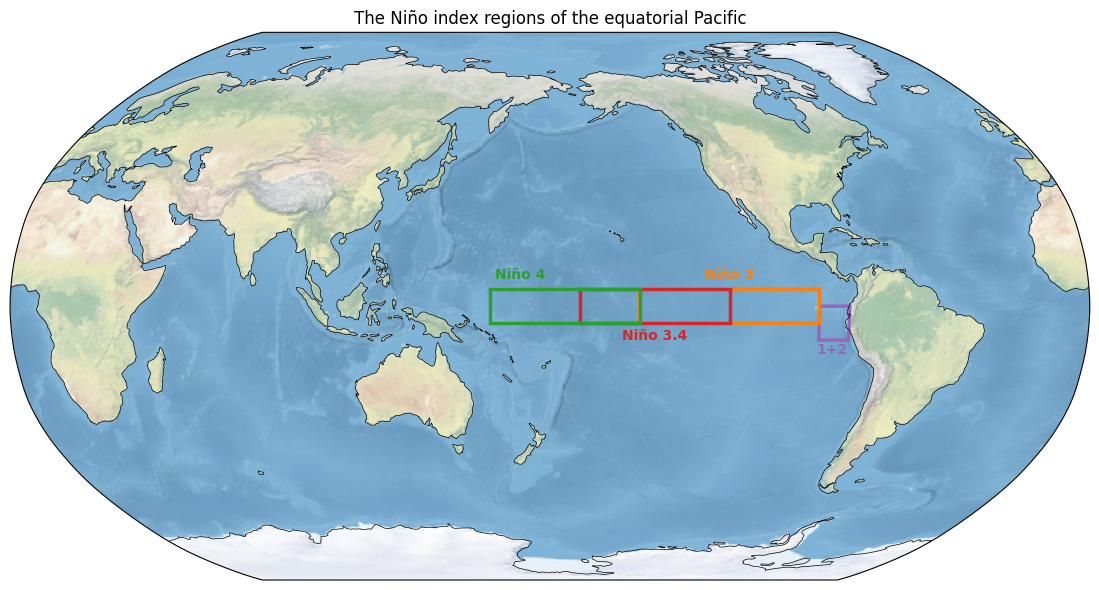

In [ ]:
# ---- The Niño boxes, in 0-360°E longitude convention ----
NINO = {  # name: (lon_min, lon_max, lat_min, lat_max, color)
    "Niño 1+2": (270, 280, -10,  0, "tab:purple"),
    "Niño 3":   (210, 270,  -5,  5, "tab:orange"),
    "Niño 3.4": (190, 240,  -5,  5, "tab:red"),
    "Niño 4":   (160, 210,  -5,  5, "tab:green"),
}

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.stock_img()                       # a 'realistic' shaded-relief Earth that ships with cartopy
ax.coastlines(lw=0.5)
for name, (x0, x1, y0, y1, c) in NINO.items():
    ax.add_patch(mpatches.Rectangle((x0, y0), x1-x0, y1-y0,
                 transform=ccrs.PlateCarree(), fill=False, edgecolor=c, lw=2.5))
ax.text(275, -14, "1+2", color="tab:purple", transform=ccrs.PlateCarree(), ha="center", weight="bold")
ax.text(240,   8, "Niño 3", color="tab:orange", transform=ccrs.PlateCarree(), ha="center", weight="bold")
ax.text(215, -10, "Niño 3.4", color="tab:red", transform=ccrs.PlateCarree(), ha="center", weight="bold")
ax.text(170,   8, "Niño 4", color="tab:green", transform=ccrs.PlateCarree(), ha="center", weight="bold")
ax.set_global()
ax.set_title("The Niño index regions of the equatorial Pacific")
plt.tight_layout()

> ### Note:
We use the **Robinson projection**: a deliberate compromise that distorts *everything a little* so the whole Earth looks natural at a glance. This is good for orientation, but bad for reading data off tropics-only plots, so later sections switch to be zoomed on the Pacific.

---
## 3. CMIP6 model, with five scenarios (aka experiments)

Each group will focus on **one** CMIP model, IPSL-CM6A (Fr), UKESM1 (UK), CESM2 (US), or GFDL-ESM4 (US). These are all the models behind the IPCC AR6 report. We have the following scenarios:

| Experiment | Years | Description |
|---|---|---|
| `historical` | 1850–2014 | the model's run of the industrial era, driven by observed forcings (greenhouse gases, aerosols, volcanoes, solar etc) |
| `ssp126` | 2015–2100 | strong-mitigation future (low emissions) |
| `ssp245` | 2015–2100 | "middle of the road" future |
| `ssp370` | 2015–2100 | regional-rivalry, high-emissions future |
| `ssp585` | 2015–2100 | very high emissions future |

Note, `historical` refers to that the model is run using the greenhouse gas forcing of the past, and is not observational data. The `ssp` ("Shared Socioeconomic Pathways") look to the future, and differ only in *forcing*, i.e. how the world changes its greenhouse gas emissions, and the physics is identical. Each scenario continues seamlessly from the end of `historical`.


---
## 4. The data fields

The class variable set with some descriptions:

| id | Quantity | Units | Table | Grid | ENSO relevance |
|---|---|---|---|---|---|
| `tos` | sea-surface temperature | °C | `Omon` | `gn` ⚠️ | the index itself is built from this |
| `zos` | sea-surface height | m | `Omon` | `gn` ⚠️ | sloshing warm water literally tilts the sea surface. It's a proxy for upper-ocean heat |
| `mlotst` | mixed-layer depth | m | `Omon` | `gn` ⚠️ | how deep the wind-stirred surface layer reaches |
| `thetao` | ocean potential temperature (3-D) | °C | `Omon` | `gn` ⚠️ | the subsurface memory of ENSO (thermocline depth, heat content) |
| `pr` | precipitation | kg m⁻² s⁻¹ | `Amon` | `gr` ✅ | Rain... Major impact we see |
| `tauu` | eastward surface wind stress | Pa | `Amon` | `gr` ✅ | the trades: ENSO's driver *and* responder |
| `tauv` | northward surface wind stress | Pa | `Amon` | `gr` ✅ | meridional component North-South |

**The grid column in important.** `gr` = regridded to a regular latitude × longitude grid: `sel(lat=..., lon=...)` just works. `gn` = the model's **native curvilinear ocean grid**: latitude and longitude are *two-dimensional arrays*, ordinary coordinate slicing fails, and regions must be selected with masks. This is a problem for most things. See Section 7 for ideas.

**Units:** precipitation arrives in kg m⁻² s⁻¹ (multiply by 86 400 for mm/day), and while IPSL's `tos` is in °C, other datasets are in Kelvin.

We load the five **2-D** fields only. `thetao` is listed, path included below, but **deliberately not loaded**: it's a 4-D field (time × 59 depth levels × y × x) roughly ~50× the data volume of `tos`. If your implementation project needs it, you can subset (tropical Pacific, upper ~300 m) *before* computing. Note `xarray` is **lazy**, so opening a store below moves no data, this only happens when you `.load()`, compute, or plot.

> **Pangeo.** Working with climate model data is very complicated. This notebook uses the same open-source stack the climate research community uses, so skills transfer.
- **intake-esm** finds and opens CMIP datasets from the cloud catalog.
- **xmip** cleans CMIP's notorious cross-model inconsistencies (coordinate names, longitude conventions, dimension order).
- **xgcm** does grid-aware calculus on staggered model grids (derivatives, transports, budget closures: not needed in this notebook, essential if your project computes heat budgets).
- **xESMF** is the community regridder (bilinear/conservative and more): We install it via conda in the setup and use it in Section 7½.
- **cf-xarray** smooths metadata handling. The free, excellent

**Project Pythia CMIP6 Cookbook** demonstrates most of this stack.


In [ ]:
import intake
import xarray as xr
from xmip.preprocessing import combined_preprocessing

# ---- Change MODEL to pick a different CMIP model. ----
MODEL = "IPSL-CM6A-LR"    # or: "IPSL-CM6A-LR", "UKESM1-0-LL", "CESM2", "GFDL-ESM4"

# Each model publishes different ensemble members, and **GFDL-ESM4 never ran ssp126** so it's missing.
# This catalog-verified lookup makes things easier for you:
WORLDS = {   # model: (default member, experiments with all six variables complete)
    "IPSL-CM6A-LR": ("r1i1p1f1", ["historical","ssp126","ssp245","ssp370","ssp585"]),
    "UKESM1-0-LL":  ("r1i1p1f2", ["historical","ssp126"]),#,"ssp245","ssp370","ssp585"]),
    "CESM2":        ("r4i1p1f1", ["historical","ssp126","ssp245","ssp370","ssp585"]),
    "GFDL-ESM4":    ("r1i1p1f1", ["historical","ssp245","ssp370","ssp585"]),
}
MEMBER, EXPS = WORLDS[MODEL]
VARS = ["tos", "zos", "mlotst", "pr", "tauu", "tauv"]

cat = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json")
found = cat.search(source_id=MODEL, member_id=MEMBER, experiment_id=EXPS,
                   variable_id=VARS, table_id=["Omon", "Amon"], grid_label=["gn", "gr"])
# Some models (CESM2) publish a variable on BOTH its native grid and a regridded one,
# so we count unique experiment/variable pairs, not rows.
expected = len(EXPS) * len(VARS)
n_unique = found.df.drop_duplicates(["experiment_id", "variable_id"]).shape[0]
assert n_unique == expected, (
    f"expected {expected} variables, found {n_unique}. Run found.df to see what exists for "
    f"{MODEL}/{MEMBER} and trim EXPS (or VARS) to what this model actually provides.")

# chunks={} keeps each store's native chunking. dask's "auto" rechunking cannot size
# cftime (object-dtype) time axes: The scenario runs extend to year 2300, beyond pandas' range.
datasets = found.to_dataset_dict(preprocess=combined_preprocessing, progressbar=False,
                                 storage_options={"token": "anon"},
                                 xarray_open_kwargs={
                                     "chunks": {},
                                     # drop bounds variables: some CMIP stores are extended to 2300 and
                                     # some are not, so their bounds conflict on merge, and we never use
                                     # them (weights come from areacello, timing from the time coordinate).
                                     "drop_variables": ["time_bnds", "time_bounds", "lat_bnds", "lon_bnds",
                                                        "bounds_lat", "bounds_lon",
                                                        "bounds_nav_lat", "bounds_nav_lon"]})

# one ocean dataset and one atmosphere dataset per experiment
ocean, atmos = {}, {}
for name in sorted(datasets):              # ".gn" sorts before ".gr", so when a variable exists on
    ds = datasets[name]                    # both grids, the native one wins (it matches areacello)
    experiment = name.split(".")[3]
    bucket = ocean if ".Omon." in name else atmos
    if experiment in bucket:
        continue                           # duplicate grid for this experiment, already have it
    ds = ds.sel(time=slice(None, "2100-12"))   # some stores extend to 2300, others don't;
                                               # keep only the range where every variable is complete
    ds = ds.squeeze(drop=True)                 # drop the singleton member/dcpp dimensions intake-esm adds
    if ".Omon." in name:
        ocean[experiment] = ds                 # holds tos, zos, mlotst (native 2-D curvilinear grid)
    else:
        # regular atmosphere grid: xmip left 1-D coordinates named y/x and added redundant,
        # transposed 2-D lat/lon copies. Keep the clean 1-D version under the proper names.
        atmos[experiment] = ds.drop_vars(["lat", "lon"]).rename({"y": "lat", "x": "lon"})

# ocean grid-cell areas for THIS model (areas are a property of the grid, so any one store will do)
import gcsfs
fs = gcsfs.GCSFileSystem(token="anon")
cell_areas = cat.search(source_id=MODEL, variable_id="areacello", grid_label="gn").df
area = xr.open_zarr(fs.get_mapper(cell_areas.zstore.iloc[0]),
                    consolidated=True)["areacello"].squeeze()

# Look at units before trusting anything!!
for ds in (ocean["historical"], atmos["historical"]):
    for v in ds.data_vars:
        print(f"{v:<7} units={ds[v].attrs.get('units','?'):<14} dims={list(ds[v].dims)}")

zos     units=m              dims=['time', 'y', 'x']
tos     units=°C             dims=['time', 'y', 'x']
mlotst  units=m              dims=['time', 'y', 'x']
pr      units=kg/m²/s        dims=['time', 'lat', 'lon']
tauu    units=Pa             dims=['time', 'lat', 'lon']
tauv    units=Pa             dims=['time', 'lat', 'lon']


> **Design decision: We're loading the intake-esm which queries the live cloud catalog** and **xmip**'s `combined_preprocessing` standardizes every dataset's coordinates (2-D `lat`/`lon` on ocean grids, longitudes in 0–360°, consistent dimension names). This cleaning makes multi-model work survivable, and the reason your project's five-model code can look like its one-model code.


Note what just printed: the three ocean fields carry 2-D latitude/longitude (the curvilinear grid, exactly as warned), the three atmosphere fields are regular. xmip has already standardized the coordinate names, so grabbing them takes two lines:


In [ ]:
# xmip has already standardized the ocean grid's coordinates: 2-D arrays named lat/lon, longitudes 0-360.
LAT2D = ocean["historical"].lat
LON360 = ocean["historical"].lon
print("ocean grid shape:", LAT2D.shape)

ocean grid shape: (332, 362)


---
## 5. Some figures from the end of the scenario run

We plot, for illustration, one map snap-shot per experiment: the **final December**, Dec **2014** for `historical`, and Dec **2100** for each SSP.


Note: The ocean-grid maps also apply a **display-only seam mask**. These are cells where the native grid wraps its longitude seam, plus cells jumping across its northern fold, project as map-wide horizontal stripes, so we blank both for plotting, else it looks weird.


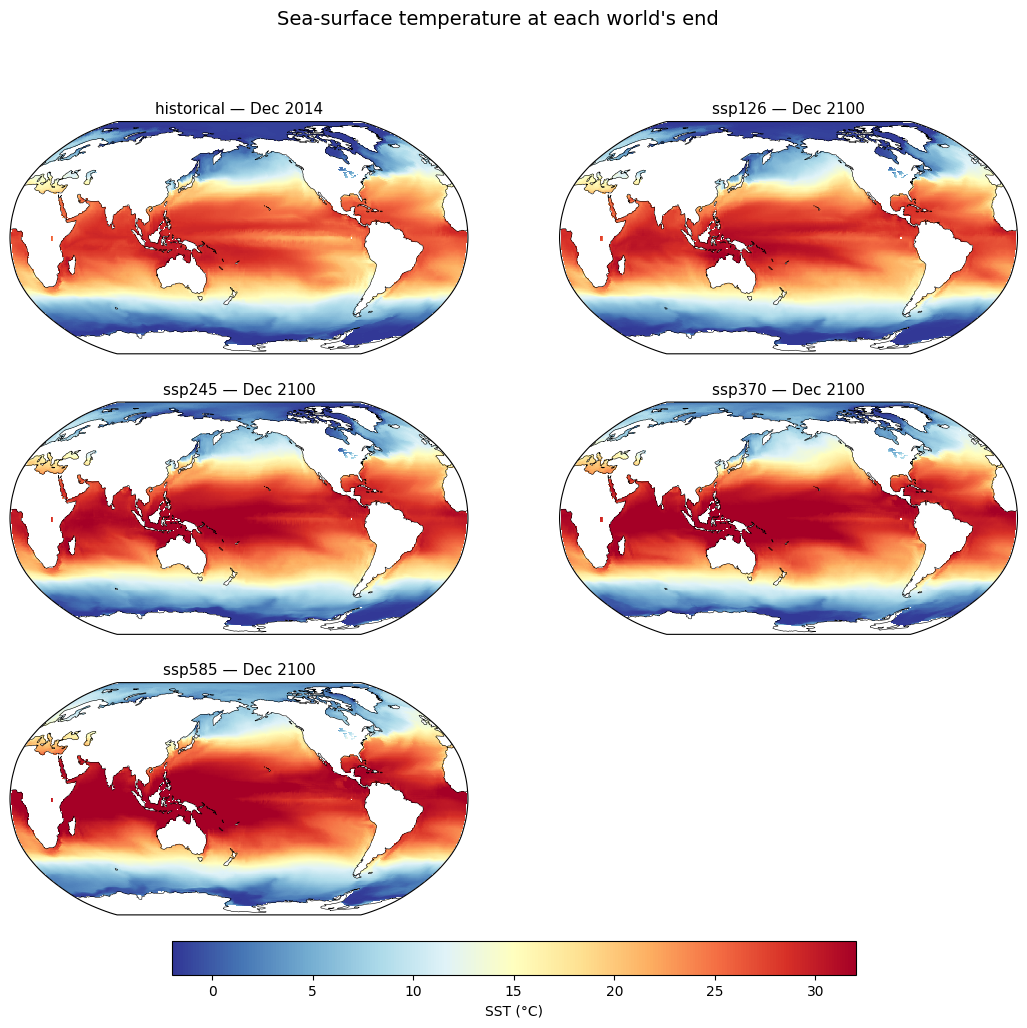

In [ ]:
# Cells where the curved ocean grid wraps its seam (or folds near the poles) smear into
# map-wide stripes when plotted. We blank those cells FOR DISPLAY ONLY
jump_lon = np.abs(np.diff(LON360.values, axis=1)) > 180
jump_lat = np.abs(np.diff(LAT2D.values,  axis=1)) > 10
bad = jump_lon | jump_lat
HIDE = np.zeros(LON360.shape, bool); HIDE[:, 1:] |= bad; HIDE[:, :-1] |= bad

def panels(fields, title, cmap, vmin, vmax, units, on_ocean_grid):
    n = len(fields); rows = (n + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(13, 3.7 * rows),
        subplot_kw={"projection": ccrs.Robinson(central_longitude=180)})
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]: ax.set_visible(False)
    for ax, (label, f) in zip(axes, fields.items()):
        if on_ocean_grid:
            f = np.where(HIDE, np.nan, np.asarray(f))
            m = ax.pcolormesh(LON360, LAT2D, f, transform=ccrs.PlateCarree(),
                              cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
        else:
            m = ax.pcolormesh(f.lon, f.lat, f, transform=ccrs.PlateCarree(),
                              cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
        ax.coastlines(lw=0.4); ax.set_global(); ax.set_title(label, fontsize=11)
    cb = fig.colorbar(m, ax=list(axes[:n]), orientation="horizontal", fraction=0.04, pad=0.03)
    cb.set_label(units); fig.suptitle(title, fontsize=14)

def last_december(ds, experiment, variable):
    month = "2014-12" if experiment == "historical" else "2100-12"
    return ds[experiment][variable].sel(time=month).squeeze().load()

labels = {e: f"{e} — Dec {'2014' if e=='historical' else '2100'}" for e in EXPS}

panels({labels[e]: last_december(ocean, e, "tos") for e in EXPS},
       "Sea-surface temperature at each world's end", "RdYlBu_r", -2, 32, "SST (°C)", True)

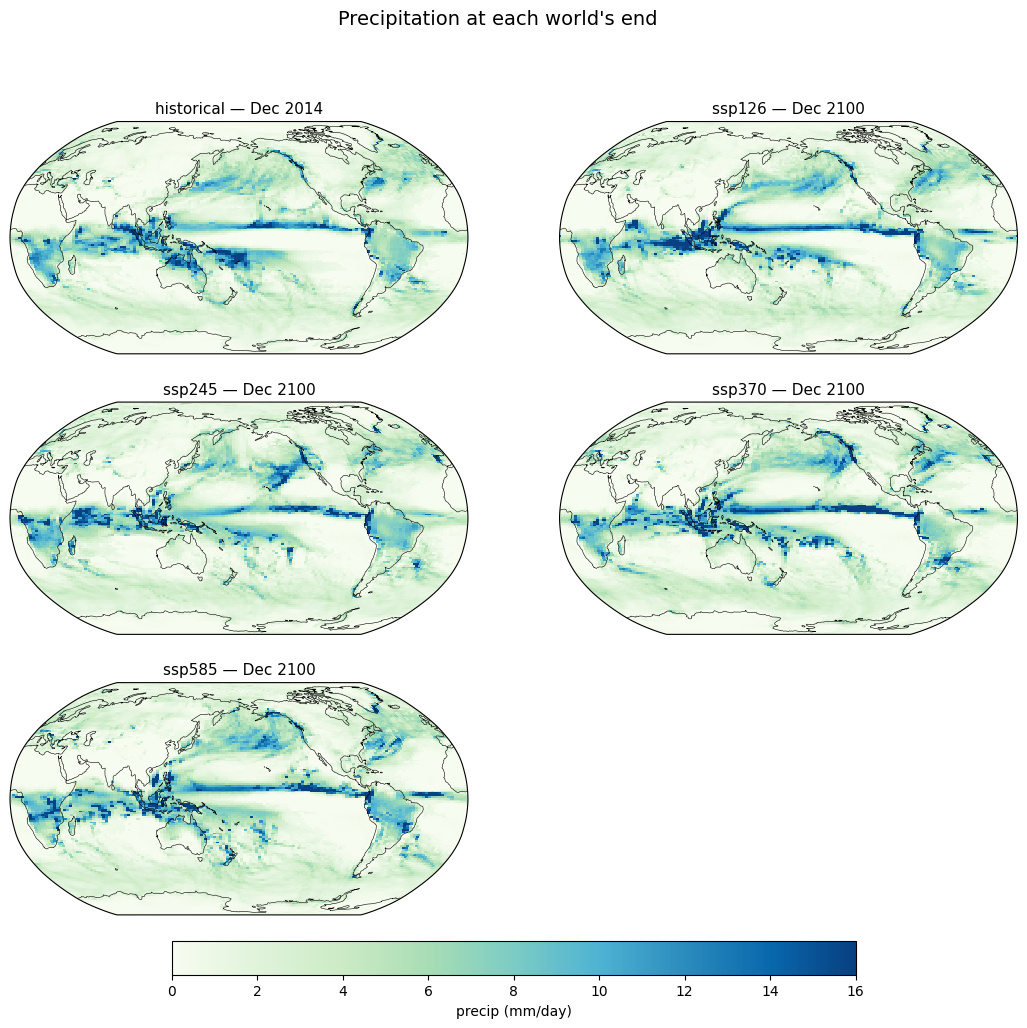

In [ ]:
panels({labels[e]: last_december(atmos, e, "pr") * 86400 for e in EXPS},
       "Precipitation at each world's end", "GnBu", 0, 16, "precip (mm/day)", False)

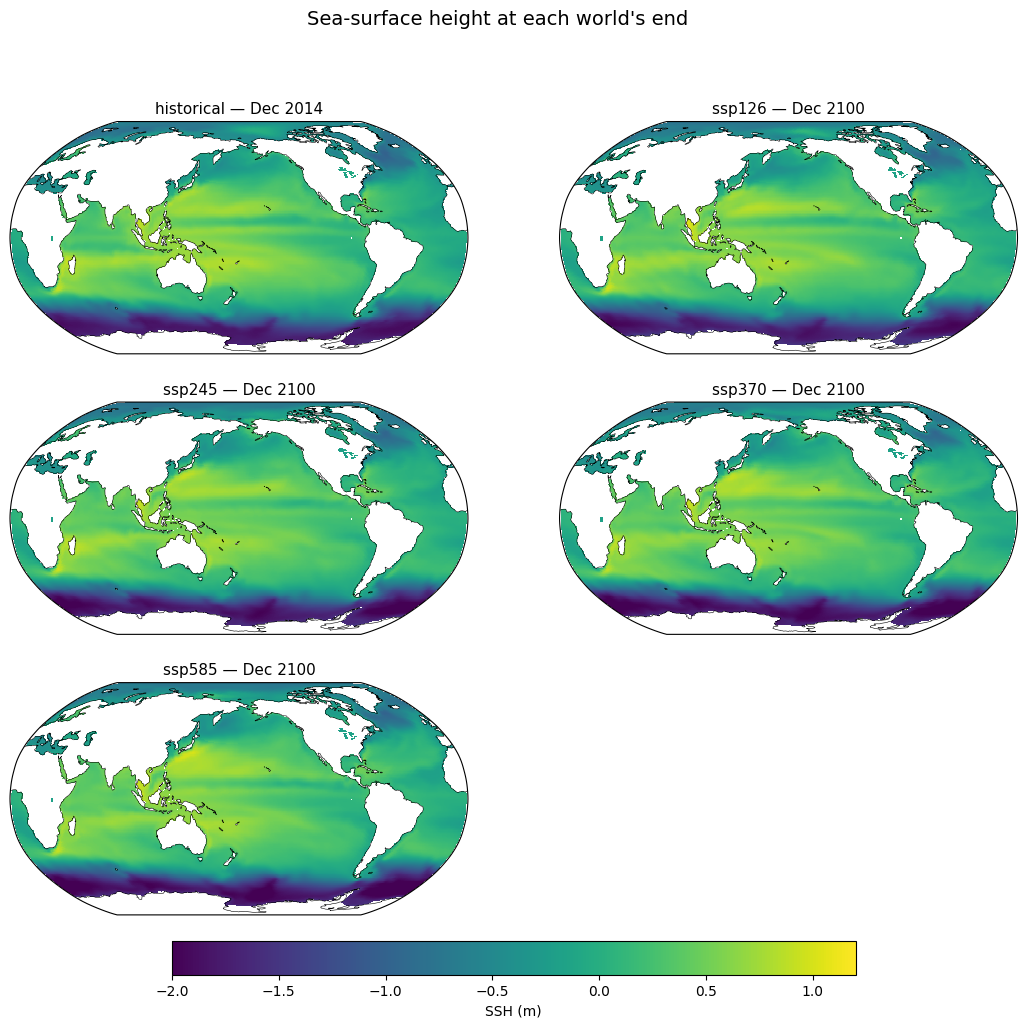

In [ ]:
panels({labels[e]: last_december(ocean, e, "zos") for e in EXPS},
       "Sea-surface height at each world's end", "viridis", -2, 1.2, "SSH (m)", True)

---
## Note: Every map above is one "frame"

Each panel in Section 5 is a **single month** sliced out of a monthly record that runs, in this archive, from 1850 to 2100 (and for some scenarios on to 2300). Roughly 3,000 months. Below, the raw (no anomaly removed) SST averaged over the Niño 3.4 box, month by month, through `historical` and `ssp585`, with dots marking the exact two frames the SST maps above showed.

The fast sawtooth that dominates the line (see inset) is the **seasonal cycle**, repeating on schedule every year and *larger* than the interannual wiggles we actually care about. Staring at it here is the motivation for everything in Section 6.


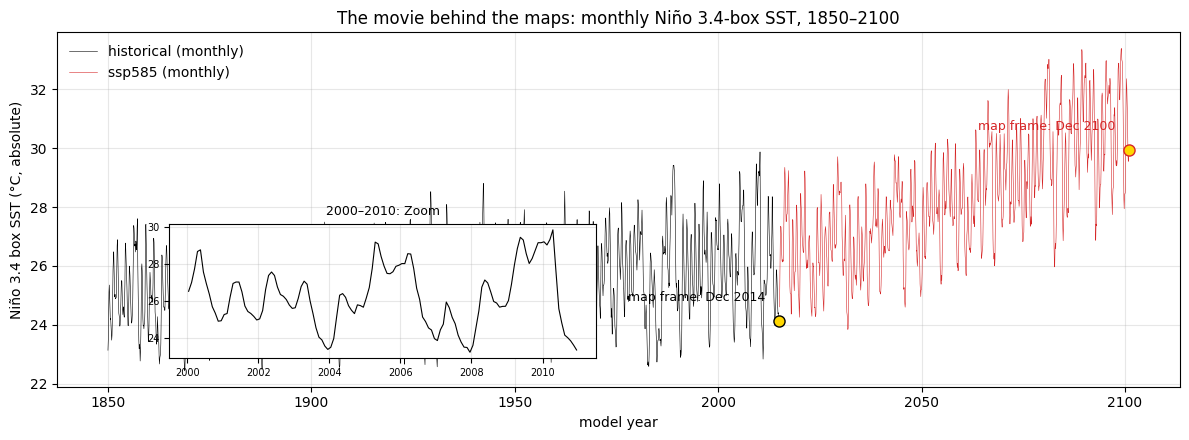

In [ ]:
# Area-weighted mean SST in the Nino 3.4 box
# applied here to ABSOLUTE SST (no anomaly yet)
lon0, lon1, lat0, lat1, _ = NINO["Niño 3.4"]
in_box = (LAT2D >= lat0) & (LAT2D <= lat1) & (LON360 >= lon0) & (LON360 <= lon1)
box_area = area.where(in_box)
box_mean = lambda da: (da * box_area).sum(dim=box_area.dims) / box_area.sum()

sst_hist = box_mean(ocean["historical"].tos).load()
sst_585  = box_mean(ocean["ssp585"].tos.sel(time=slice("2015", "2100"))).load()
years = lambda da: da.time.dt.year + (da.time.dt.month - 0.5) / 12

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(years(sst_hist), sst_hist, color="k", lw=0.4, label="historical (monthly)")
ax.plot(years(sst_585),  sst_585,  color="tab:red", lw=0.4, label="ssp585 (monthly)")
for label, series, month, color in [("map frame: Dec 2014", sst_hist, "2014-12", "k"),
                                    ("map frame: Dec 2100", sst_585,  "2100-12", "tab:red")]:
    point = series.sel(time=month).squeeze()
    ax.plot(float(years(point)), float(point), "o", ms=8, mfc="gold", mec=color, zorder=5)
    ax.annotate(label, (float(years(point)), float(point)),
                textcoords="offset points", xytext=(-10, 14), ha="right", fontsize=9, color=color)
ax.set_xlabel("model year"); ax.set_ylabel("Niño 3.4 box SST (°C, absolute)")
ax.set_title("The movie behind the maps: monthly Niño 3.4-box SST, 1850–2100")
ax.legend(frameon=False, loc="upper left"); ax.grid(alpha=0.3)

inset = ax.inset_axes([0.1, 0.08, 0.38, 0.38])
decade = sst_hist.sel(time=slice("2000", "2010"))
inset.plot(years(decade), decade, color="k", lw=0.8)
inset.set_title("2000–2010: Zoom", fontsize=9)
inset.tick_params(labelsize=7); inset.grid(alpha=0.3)
plt.tight_layout()

Above we see a clear trend. HOwever: You can tell a 1.5 °C world from a ~4 °C by looking at a spatial plot? Probaly not. The spatial pattern of climate (warm tropics, cold poles, warm-pool-and-cold-tongue Pacific) dominate the *change* in climate. This is why we look at the anomalies.

---
## 6. An anomaly

**An anomaly is the departure from what is normal for that location and that time of year.** For example:

1. Choose a **base period** such as, **1985–2014**, the last 30 years of `historical`.
2. For each of the 12 calendar months, average every January, every February, … in the base period. The result (12 maps) is the **climatology**. So the "normal."
3. Subtract from every field its month's climatology:

$$\mathrm{anomaly}(x,y,t) = \mathrm{value}(x,y,t) - \mathrm{climatology}(x,y,\mathrm{month}(t))$$

Notice: the eastern equatorial Pacific swings by *several* °C every year **on schedule**. An El Niño is a ~1–2.5 °C irregular signal. Subtracting the climatology lets the interesting irregularity stands out. Most things discussing ENSO temperature are relative to a stated base period.

The base period here is 1985–2014, and matches the current WMO-style 30-year convention and sits at the end of `historical`. But "normal" is moving: In a warming world, a late base period makes the past look cold. NOAA re-standardizes its operational base every 5 years for exactly this reason. Your project must take a documented position on this. Comparing your numbers is only meaningful if the base periods match. In class, use a standard of 1985–2014 unless reported otherwise.


In [ ]:
BASE = slice("1985-01", "2014-12")
clim = ocean["historical"].tos.sel(time=BASE).groupby("time.month").mean("time")
ssta = (ocean["historical"].tos.groupby("time.month") - clim).rename("ssta")
print("climatology:", dict(clim.sizes), "| anomaly field:", dict(ssta.sizes))

climatology: {'month': 12, 'y': 332, 'x': 362} | anomaly field: {'time': 1980, 'y': 332, 'x': 362}


---
## 7. The Niño boxes, computed on different grids

The area-averaged SST anomaly inside each box. On the native ocean grid there is no `sel(lat=slice(-5,5))`. We build a **boolean mask** from the 2-D coordinate arrays and take a **weighted** average, with the model's own grid-cell areas (`areacello`) as weights.

> **Area weighting.** Grid cells differ in size (less than you'd fear in the deep tropics, more as the mesh refines meridionally toward the equator). Weighting by true cell area is the way to go. An unweighted mean assumes all cells are equal. In the Niño boxes the numerical difference is small, but errors compound and are sneaky.


strongest simulated El Niño month: 1988-12 | peak Niño3.4 anomaly: 4.27 °C


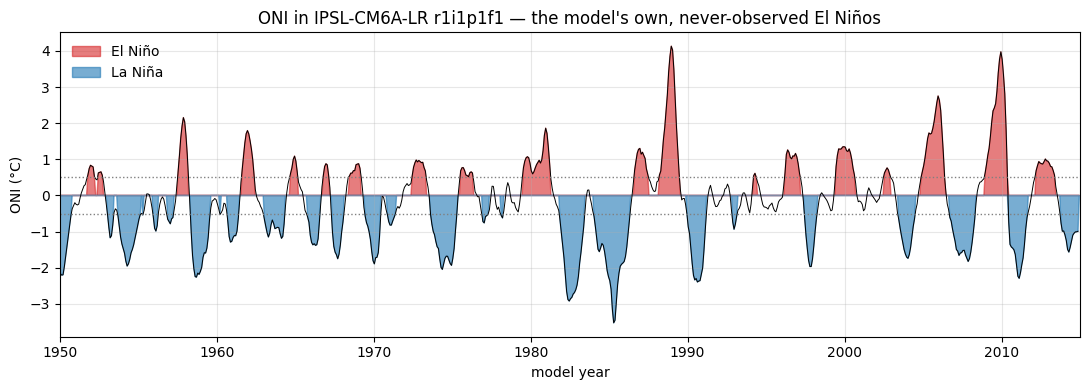

In [ ]:
# NOTE: this cell does the first real data crunching
# No output until it finishes.

def nino_index(name):
    lon0, lon1, lat0, lat1, _ = NINO[name]
    inside = (LAT2D >= lat0) & (LAT2D <= lat1) & (LON360 >= lon0) & (LON360 <= lon1)
    w = area.where(inside)
    return ((ssta * w).sum(dim=w.dims) / w.sum()).load()

indices = {name: nino_index(name) for name in NINO}
oni = indices["Niño 3.4"].rolling(time=3, center=True).mean()   # ONI: 3-month running mean

fig, ax = plt.subplots(figsize=(11, 4))
t = oni.time.dt.year + (oni.time.dt.month - 0.5)/12
ax.fill_between(t, 0, oni.where(oni >=  0.5, 0), color="tab:red",  alpha=.6, label="El Niño")
ax.fill_between(t, 0, oni.where(oni <= -0.5, 0), color="tab:blue", alpha=.6, label="La Niña")
ax.plot(t, oni, "k", lw=0.7)
for y in (0.5, -0.5): ax.axhline(y, ls=":", lw=1, color="gray")
ax.set_xlim(1950, 2015); ax.set_xlabel("model year"); ax.set_ylabel("ONI (°C)")
ax.set_title(f"ONI in {MODEL} {MEMBER} — the model's own, never-observed El Niños")
ax.legend(frameon=False); ax.grid(alpha=0.3); plt.tight_layout()

peak = str(indices["Niño 3.4"].idxmax("time").values)[:7]
print("strongest simulated El Niño month:", peak,
      "| peak Niño3.4 anomaly: %.2f °C" % float(indices["Niño 3.4"].max()))

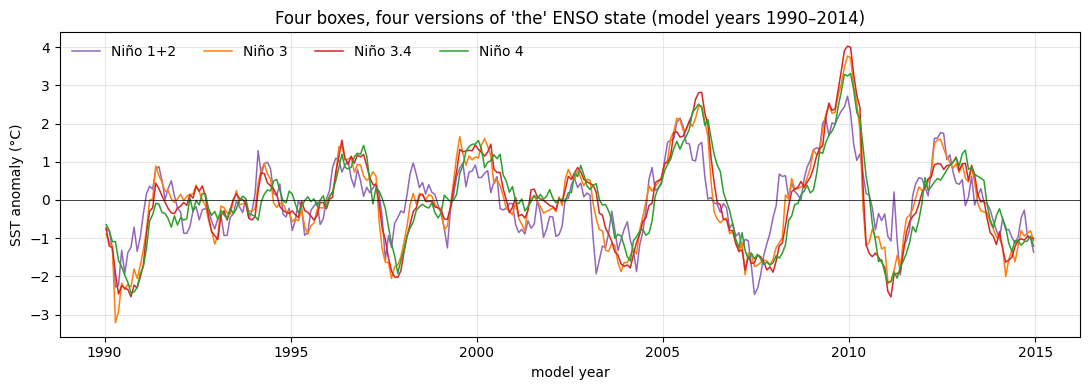

In [ ]:
# All four indices during one simulated event-rich stretch
fig, ax = plt.subplots(figsize=(11, 4))
for name, (_, _, _, _, c) in NINO.items():
    sel = indices[name].sel(time=slice("1990", "2014"))
    ax.plot(sel.time.dt.year + (sel.time.dt.month-0.5)/12, sel, color=c, lw=1.1, label=name)
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("SST anomaly (°C)"); ax.set_xlabel("model year")
ax.set_title("Four boxes, four versions of 'the' ENSO state (model years 1990–2014)")
ax.legend(frameon=False, ncol=4); ax.grid(alpha=0.3); plt.tight_layout()

---
## Converting between Grids

Our seven variables live on **two different grids** (Section 4). The moment you want them to talk to each other -> correlate SST with rainfall, stack both into one ML feature tensor etc one of them must move. This is **regridding** and every method invents or destroys information somewhere.

> **xESMF, the community standard.** Regridding is a pain. We regrid with **xESMF**, wrapping NOAA's ESMF library. The same `Regridder` object does `bilinear` (used here: smooth interpolation, right for continuous fields like SST), `conservative` (preserves area integrals good choice for fluxes and budgets), and `nearest_s2d` (moves exact values, no invention). `periodic=True` tells it the globe wraps in longitude; `ignore_degenerate=True` tolerates the collapsed cells near the ocean grid's folded poles. Direction of travel: fine ocean grid → coarser atmosphere grid. The reverse would manufacture resolution that does not exist. Tip: Don't regrid inside a training loop.


In [ ]:
#import xesmf as xe
import os
if "ESMFMKFILE" not in os.environ:                       # conda sets this on activation;
    os.environ["ESMFMKFILE"] = "/usr/local/lib/esmf.mk"  # the Colab kernel never activates, so we do it
import esmpy.api.locstream   # newer esmpy stopped auto-importing its api subpackage; xesmf still expects it
import xesmf as xe

# build the ocean->atmosphere regridder. Apply it to any field on the ocean grid
regridder = xe.Regridder(ocean["historical"], atmos["historical"], "bilinear",
                         periodic=True, ignore_degenerate=True)

ssta_peak = ssta.sel(time=peak).squeeze().load()
ssta_reg = regridder(ssta_peak)
print("regridded:", dict(ssta_peak.sizes), "->", dict(ssta_reg.sizes))

regridded: {'y': 332, 'x': 362} -> {'lat': 143, 'lon': 144}


In [ ]:
import esmpy, xesmf; print(esmpy.__version__, xesmf.__version__)

8.9.1 0.9.2


pattern correlation, SST vs rainfall anomaly (tropical Pacific, 1988-12): r = +0.45


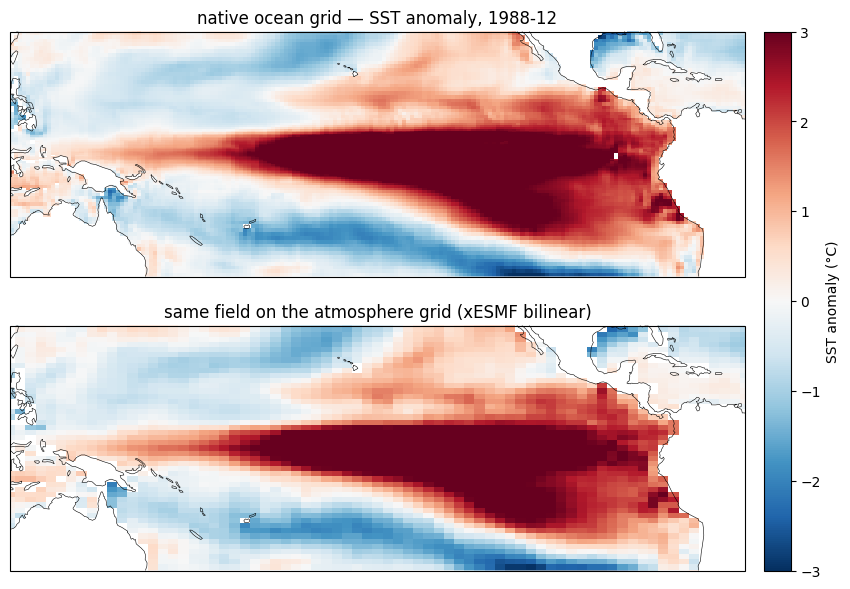

In [ ]:
# Before and after
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)})

ax1.pcolormesh(LON360, LAT2D, np.where(HIDE, np.nan, ssta_peak), transform=ccrs.PlateCarree(),
               cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
ax1.set_title(f"native ocean grid — SST anomaly, {peak}")

m = ax2.pcolormesh(ssta_reg.lon, ssta_reg.lat, ssta_reg, transform=ccrs.PlateCarree(),
                   cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
ax2.set_title("same field on the atmosphere grid (xESMF bilinear)")

for ax in (ax1, ax2):
    ax.coastlines(lw=0.4); ax.set_extent([120, 300, -30, 30], ccrs.PlateCarree())
fig.colorbar(m, ax=[ax1, ax2], fraction=0.03, pad=0.02, label="SST anomaly (°C)")

# Huzzah! SST and rainfall now share a grid, so point-wise statistics are OK!
pr_clim = atmos["historical"].pr.sel(time=BASE).groupby("time.month").mean("time")
pr_anom = ((atmos["historical"].pr.groupby("time.month") - pr_clim)
           .sel(time=peak).squeeze() * 86400).load()
r = xr.corr(ssta_reg.sel(lat=slice(-15, 15), lon=slice(140, 280)),
            pr_anom.sel(lat=slice(-15, 15), lon=slice(140, 280)))
print(f"pattern correlation, SST vs rainfall anomaly (tropical Pacific, {peak}): r = {float(r):+.2f}")

---
# Examples of predictive models to get you started

### Persistence
The baseline for forecast skill is **persistence.**
That is, "next month's Pacific looks like this month's": forecast(t + lead) = ONI(t).
The skill here is simply how correlated the index is with its own future.

### Linear Inverse Model
The classic statistical ENSO forecaster (Penland & Sardeshmukh 1995) assumes linear dynamics plus some noise. It estimates the one-month propagator G from data, forecast by applying it repeatedly.
Here, the state vector is the four Niño indices, which we fit on the first 100 years.



persistence stays above r = 0.5 out to ~6 months lead


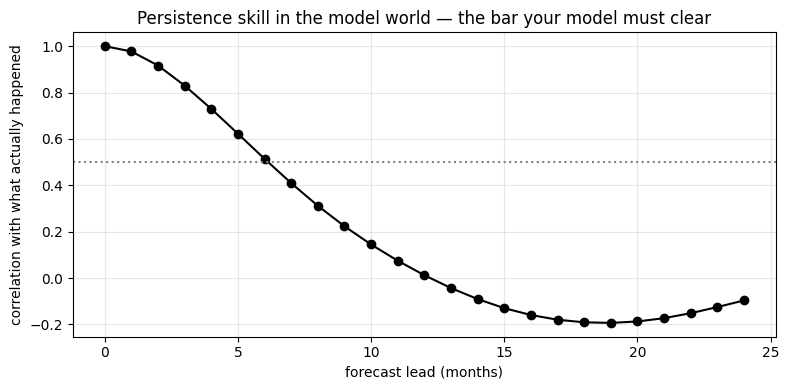

In [ ]:

# Persistence

leads = np.arange(0, 25)
skill = [float(xr.corr(oni, oni.shift(time=-int(l)))) for l in leads]

plt.figure(figsize=(8, 4))
plt.plot(leads, skill, "o-", color="k")
plt.axhline(0.5, ls=":", color="gray")
plt.xlabel("forecast lead (months)"); plt.ylabel("correlation with what actually happened")
plt.title("Persistence skill in the model world — the bar your model must clear")
plt.grid(alpha=0.3); plt.tight_layout()
print(f"persistence stays above r = 0.5 out to ~{int(leads[np.array(skill) >= 0.5].max())} months lead")

propagator spectral radius: 0.964 (<1 = damped, as physics demands)


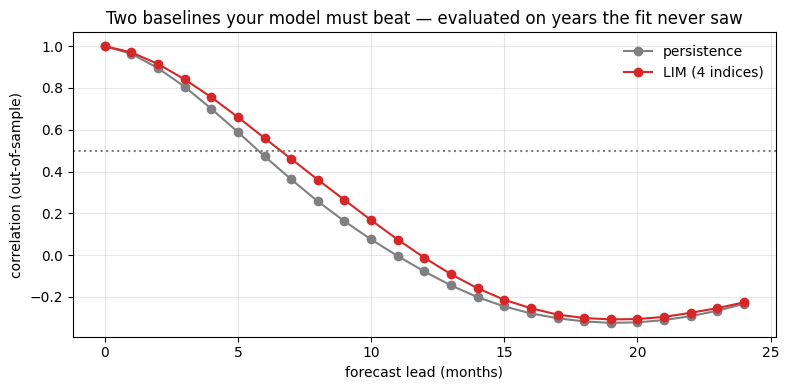

In [ ]:
# A simple Linear INverse Model
X = np.stack([indices[name].values for name in NINO])     # shape (4, n_months)
n_train = 1200                                            # 100 years of monthly data
i34 = list(NINO).index("Niño 3.4")

X0, X1 = X[:, :n_train-1], X[:, 1:n_train]
G = (X1 @ X0.T) @ np.linalg.inv(X0 @ X0.T)                # one-month propagator: G = C(1) C(0)^-1
print("propagator spectral radius:", round(max(abs(np.linalg.eigvals(G))), 3), "(<1 = damped, as physics demands)")

lim_skill, pers_skill = [], []
truth_all = X[i34]
for lead in leads:                                        # 'leads' from the persistence cell
    pred = (np.linalg.matrix_power(G, int(lead)) @ X[:, n_train:])[i34]
    truth = truth_all[n_train + lead:]
    lim_skill.append(np.corrcoef(pred[:truth.size], truth)[0, 1])
    pers_skill.append(np.corrcoef(truth_all[n_train:truth.size + n_train], truth)[0, 1])

plt.figure(figsize=(8, 4))
plt.plot(leads, pers_skill, "o-", color="gray", label="persistence")
plt.plot(leads, lim_skill, "o-", color="tab:red", label="LIM (4 indices)")
plt.axhline(0.5, ls=":", color="gray")
plt.xlabel("forecast lead (months)"); plt.ylabel("correlation (out-of-sample)")
plt.title("Two baselines your model must beat — evaluated on years the fit never saw")
plt.legend(frameon=False); plt.grid(alpha=0.3); plt.tight_layout()

_________
# The prediction task.

You will build a machine that forecasts ENSO. Formally: given tropical-Pacific anomaly fields up to some month t, predict the Niño 3.4 index at month t + τ, where τ = [3] months — the lead implied. Start the forecast a few months before today, so we can evaluate at the end on the class.

You will train your model only on CMIP. Evaluate it on held-out simulation years, and use a real-world hindcast file (a model estimating the past by being fit to existing observational data) to issue your forecast. The hindcast files will be shared in Week 5.

Your inputs can be anything you like, e.g. maps, mean values in the boxes... feel free to use persistence and the LIM as baselines to beat.


Deliverables: (1) A 2-page report, (2) Your recording, and (3) your forecast + code.

See syllabus for GenAI policies.


